# P11 Piloter un projet data augmenté avec l'IA

## (P6 Optimiser la gestion & nettoyer les données du stock de Bottleneck)  

## Objectifs :  
Analyser les prix, les ventes et les stocks des produits commercialisés en ligne par l'entreprise Bottleneck, à travers les étapes suivantes :  
- **Agréger les données :** fusionner les données de l'ERP (prix de vente, prix d'achat et stocks) avec les données du site web (noms des produits, catégories et quantités vendues) afin de constituer un jeu de données exploitable.
- **Exploiter et analyser les données :** étudier notamment les prix et les corrélations entre les stocks, les ventes et les prix.
- **Formuler des recommandations :** proposer des actions d'amélioration adaptées aux résultats des analyses.

# Préparation de l'environnement d'exécution

## Importation des bibliothèques

In [1]:
# Importer le module sys
import sys
# Importer la bibliothèque Pandas
import pandas as pd
# Importer la bibliothèque Numpy
import numpy as np
# Importer la bibliothèque Plotly Express
import plotly.express as px
# Importer le module Pandera pour pandas
import pandera.pandas as pa

## Vérification de l'environnement d'exécution

In [2]:
# Afficher la version de Python
print("Version de Python :", sys.version)
# Afficher le chemin de l'interpréteur Python
print(f"Environnement Python : {sys.executable}")
# Afficher la version de Pandas
print(f"Version de Pandas : {pd.__version__}")
# Afficher la version de NumPy
print(f"Version de NumPy : {np.__version__}")

from importlib.metadata import version
# Afficher la version de Plotly
print(f"Version de Plotly : {version('plotly')}")
# Afficher la version de Pandera
print(f"Version de Pandera : {version('pandera')}")

Version de Python : 3.13.18 | packaged by Anaconda, Inc. | (main, Oct 27 2026, 00:53:21) [MSC v.1942 64 bit (AMD64)]
Environnement Python : C:\Users\yingf\anaconda3\envs\pandas3_env\python.exe
Version de Pandas : 3.0.6
Version de NumPy : 2.3.5
Version de Plotly : 7.1.0
Version de Pandera : 0.36.0


## Configuration de l'affichage des données

In [3]:
# Afficher toutes les colonnes des DataFrames
pd.set_option("display.max_columns", None)
# Uniformiser l'affichage des valeurs numériques à deux décimales
pd.set_option("display.float_format", "{:,.2f}".format)

# 1. Importation des fichiers

In [4]:
# Importer le fichier erp.xlsx
df_erp = pd.read_excel("erp.xlsx")
# Importer le fichier web.xlsx
df_web = pd.read_excel("web.xlsx")
# Importer le fichier liaison.xlsx
df_liaison = pd.read_excel("liaison.xlsx")

C:\Users\yingf\anaconda3\envs\pandas3_env\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
C:\Users\yingf\anaconda3\envs\pandas3_env\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
C:\Users\yingf\anaconda3\envs\pandas3_env\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


**Remarque sur l'avertissement openpyxl :**  
L'avertissement généré par openpyxl concerne une fonctionnalité Excel non prise en charge, sans incidence sur les données utilisées dans cette analyse.

# 2. Exploration des fichiers

## 2.1 Fichier ERP

In [5]:
# Afficher les dimensions du jeu de données
print("Le tableau ERP comporte {} ligne(s) et {} colonne(s).".format(df_erp.shape[0], df_erp.shape[1]))

Le tableau ERP comporte 825 ligne(s) et 6 colonne(s).


In [6]:
# Examiner la structure du jeu de données
df_erp.info()

<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    str    
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 38.8 KB


In [7]:
# Ajuster le type de données de la colonne « product_id »
df_erp['product_id'] = df_erp['product_id'].astype(str)

In [8]:
# Afficher un aperçu du jeu de données
df_erp

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.20,16,instock,12.88
1,3849,1,34.30,10,instock,17.54
2,3850,1,20.80,0,outofstock,10.64
3,4032,1,14.10,26,instock,6.92
4,4039,1,46.00,3,outofstock,23.77
...,...,...,...,...,...,...
820,7203,0,45.00,30,instock,23.48
821,7204,0,45.00,9,instock,24.18
822,7247,1,54.80,6,instock,27.18
823,7329,0,26.50,14,instock,13.42


### Validation initiale des données avec Pandera

In [9]:
# Créer une copie du jeu de données ERP pour la validation avec Pandera
df_erp_pandera = df_erp.copy()

**Définition des règles de validation :**  
- Cohérence du stock : vérifier la cohérence entre stock_quantity et stock_status : Quantité > 0 : instock, Quantité ≤ 0 : outofstock.
- « product_id » : absence de valeurs manquantes et de doublons.
- « onsale_web » : valeurs binaires (0 ou 1) et absence de valeurs manquantes.
- « price » : valeur strictement positive (> 0) et absence de valeurs manquantes.
- « stock_quantity » : valeur positive ou nulle (≥ 0) et absence de valeurs manquantes.
- « stock_status » : valeurs limitées à instock et outofstock, sans valeurs manquantes.
- « purchase_price » : valeur strictement positive (> 0) et absence de valeurs manquantes.

In [10]:
# Vérifier la cohérence entre le statut et la quantité de stock
check_stock = pa.Check(
    lambda df: (
        ((df["stock_quantity"] > 0) & (df["stock_status"] == "instock")) 
        | 
        ((df["stock_quantity"] <= 0) & (df["stock_status"] == "outofstock"))
    ),
    name="coherence_stock"
)

# Définir le schéma de validation
schema_erp = pa.DataFrameSchema(
    {
        "product_id": pa.Column(nullable=False, unique=True),
        "onsale_web": pa.Column(int, pa.Check.isin([0, 1]), nullable=False),
        "price": pa.Column(float, pa.Check.gt(0), nullable=False),
        "stock_quantity": pa.Column(int, pa.Check.ge(0), nullable=False),
        "stock_status": pa.Column(checks=pa.Check.isin(["instock", "outofstock"]), nullable=False),
        "purchase_price": pa.Column(float, pa.Check.gt(0), nullable=False)
    },
    checks=[check_stock],
    strict=True
)

In [11]:
# Valider les données ERP
try:
    schema_erp.validate(df_erp_pandera, lazy=True)
    validation_reussie = True
    anomalies = pd.DataFrame()

except pa.errors.SchemaErrors as e:
    validation_reussie = False
    anomalies = e.failure_cases.copy()

In [12]:
# Afficher les résultats de validation

print(f"Validation réussie : {validation_reussie}")

rapport_pandera_erp = []

if validation_reussie:
    print("Aucune anomalie détectée.")

else:
    # Regrouper les anomalies par colonne et par règle
    for (colonne, regle), groupe in anomalies.groupby(
        ["column", "check"], dropna=False
    ):

        # Traiter séparément la cohérence du stock
        if regle == "coherence_stock":
            continue

        # Identifier le type d'anomalie
        if colonne == "stock_quantity" and str(regle).startswith("greater_than_or_equal_to"):
            anomalie = "Stock négatif"

        elif colonne in ["price", "purchase_price"] and str(regle).startswith("greater_than"):
            anomalie = "Prix invalide"

        elif str(regle).startswith("dtype"):
            anomalie = "Type de données"

        else:
            anomalie = str(regle)

        # Récupérer les index des lignes concernées
        index = groupe["index"].dropna().unique().tolist()

        if str(regle).startswith("dtype") or not index:
            nombre = "Colonne entière"
            index = "Colonne entière"
        else:
            nombre = len(index)

        rapport_pandera_erp.append({
            "colonne": colonne,
            "anomalie": anomalie,
            "nombre": nombre,
            "index": index
        })

    # Regrouper les anomalies de cohérence du stock
    anomalies_stock = anomalies[
        anomalies["check"] == "coherence_stock"
    ]

    if not anomalies_stock.empty:
        index_stock = anomalies_stock["index"].dropna().unique().tolist()

        rapport_pandera_erp.append({
            "colonne": "stock_status",
            "anomalie": "Cohérence du stock",
            "nombre": len(index_stock),
            "index": index_stock
        })

# Créer et afficher le rapport
rapport_pandera_erp = pd.DataFrame(
    rapport_pandera_erp,
    columns=["colonne", "anomalie", "nombre", "index"]
)

display(rapport_pandera_erp)

Validation réussie : False


,colonne,anomalie,nombre,index
0,price,Prix invalide,3,"[469, 739, 151]"
1,stock_quantity,Stock négatif,2,"[573, 449]"
2,stock_status,Cohérence du stock,2,"[398, 4]"


### Nettoyage des données

#### - « price »

**Règle de traitement des prix invalides (≤ 0) :**  
- Les prix invalides peuvent résulter d'erreurs de saisie ou de problèmes système. Les enregistrements sont conservés pour une vérification manuelle ultérieure.
- Ils sont toutefois exclus de l'analyse afin d'éviter de fausser les indicateurs et les analyses de corrélation.

In [13]:
# Conserver les enregistrements dont le prix est invalide
prix_invalides = df_erp.loc[df_erp["price"] <= 0]
display(prix_invalides)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
151,4233,0,-20.00,0,outofstock,10.33
469,5017,0,-8.00,0,outofstock,4.34
739,6594,0,-9.10,19,instock,4.61


In [14]:
# Conserver les enregistrements dont le prix est valide pour l'analyse
df_erp = df_erp[df_erp["price"] > 0]

In [15]:
# Vérifier l'absence de prix invalides (≤ 0)
print("Nombre d'articles avec un prix invalide : {}".format((df_erp['price'] <= 0).sum()))

Nombre d'articles avec un prix invalide : 0


#### - « stock_quantity »

**Règle de traitement des stocks négatifs :**  
Les quantités en stock négatives ne sont pas systématiquement considérées comme des anomalies, car elles peuvent être autorisées par certaines règles de gestion ERP (survente, décalage de synchronisation ou ajustement d'inventaire). En l'absence de confirmation des règles métier applicables, aucune correction automatique n'est effectuée afin de préserver les données d'origine.

#### - « stock_status »

In [16]:
# Corriger les incohérences entre la colonne « stock_quantity » et la colonne « stock_status »

# Cas 1 : « stock_quantity » > 0 → « stock_statut » = instock
df_erp.loc[
    (df_erp['stock_quantity'] > 0) &
    (df_erp['stock_status'] == 'outofstock'),
    'stock_status'
] = 'instock'
# Cas 2 : « stock_quantity » <=0 → « stock_statut » = outofstock
df_erp.loc[
    (df_erp['stock_quantity'] <= 0) &
    (df_erp['stock_status'] == 'instock'),
    'stock_status'
] = 'outofstock'

In [17]:
# Vérifier les résultats après correction
verif_incoherences = df_erp[
    ((df_erp['stock_quantity'] > 0) & (df_erp['stock_status'] == 'outofstock')) |
    ((df_erp['stock_quantity'] <= 0) & (df_erp['stock_status'] == 'instock'))
]

if len(verif_incoherences) == 0:
    print("Aucune incohérence détectée entre le statut et la quantité de stock.")
else:
    print(f"Attention : {len(verif_incoherences)} incohérence(s) détectée(s), à vérifier.")

Aucune incohérence détectée entre le statut et la quantité de stock.


#### - « onsale_web »

La variable « onsale_web » est une **variable binaire** :  
- 1 : le produit est commercialisé en ligne.
- 0 : le produit n'est pas commercialisé en ligne.

In [18]:
# Ajuster la colonne « onsale_web » en type booléen
df_erp = df_erp.astype({"onsale_web": bool})

### Jeu de données ERP finalisé

In [19]:
# Afficher la structure du jeu de données finalisé
df_erp.info()

<class 'pandas.DataFrame'>
Index: 822 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      822 non-null    str    
 1   onsale_web      822 non-null    bool   
 2   price           822 non-null    float64
 3   stock_quantity  822 non-null    int64  
 4   stock_status    822 non-null    str    
 5   purchase_price  822 non-null    float64
dtypes: bool(1), float64(2), int64(1), str(2)
memory usage: 39.3 KB


## 2.2 Fichier WEB 

In [20]:
# Afficher les dimensions du jeu de données
print("Le tableau WEB comporte {} ligne(s) et {} colonne(s).".format(df_web.shape[0],df_web.shape[1]))

Le tableau WEB comporte 1513 ligne(s) et 29 colonne(s).


In [21]:
# Examiner la structure du jeu de données
df_web.info()

<class 'pandas.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    str           
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[us]
 10  post_date_gmt          1430 non-null   datetime64[us]
 11  post_content           0 non-null      float64       
 12  product_type           1429 non-null   str           
 13  post_title    

In [22]:
# Ajuster le type de données de la colonne « sku »
df_web['sku'] = df_web['sku'].astype(str)

### Optimisation de la sélection des variables

In [23]:
# Analyser les nombreuses colonnes du jeu de données avant de sélectionner celles pertinentes pour l'analyse
profil_colonnes = pd.DataFrame({
    'dtype': df_web.dtypes,
    'nb_valeurs_distinctes': df_web.nunique(),
    'nb_valeurs_manquantes': df_web.isna().sum()
})

display(profil_colonnes)

,dtype,nb_valeurs_distinctes,nb_valeurs_manquantes
sku,str,714,85
virtual,int64,1,0
downloadable,int64,1,0
rating_count,int64,1,0
average_rating,float64,1,83
total_sales,float64,29,83
tax_status,str,1,797
tax_class,float64,0,1513
post_author,float64,2,83
post_date,datetime64[us],716,83


**Sélection automatique des variables**  
Les règles de suppression suivantes sont appliquées :  
- Colonnes entièrement vides : suppression des colonnes contenant uniquement des valeurs manquantes.
- Colonnes constantes : suppression des colonnes dont toutes les observations présentent une seule et même valeur, sans valeur manquante.

In [24]:
# Identifier les colonnes entièrement vides
colonnes_vides = profil_colonnes[
    profil_colonnes['nb_valeurs_manquantes'] == len(df_web)
].index.tolist()
# Identifier les colonnes constantes sans valeurs manquantes
colonnes_constantes = profil_colonnes[
    (profil_colonnes['nb_valeurs_distinctes'] == 1) &
    (profil_colonnes['nb_valeurs_manquantes'] == 0)
].index.tolist()

# Suppression automatique
colonnes_a_supprimer = colonnes_vides + colonnes_constantes
df_web = df_web.drop(columns=colonnes_a_supprimer)

# Synthèse
print(f"Colonnes entièrement vides supprimées : {len(colonnes_vides)}")
print(f"Colonnes constantes supprimées : {len(colonnes_constantes)}")
print("\nColonnes supprimées :", colonnes_a_supprimer)

Colonnes entièrement vides supprimées : 4
Colonnes constantes supprimées : 3

Colonnes supprimées : ['tax_class', 'post_content', 'post_password', 'post_content_filtered', 'virtual', 'downloadable', 'rating_count']


### Validation initiale des données avec Pandera

In [25]:
# Créer une copie pour la validation avec Pandera
df_web_pandera = df_web.copy()

In [26]:
# Définir le schéma de validation
schema_web = pa.DataFrameSchema(
    {
        "sku": pa.Column(checks=pa.Check(lambda s: s.str.fullmatch(r"\d+"), name="format_sku"), nullable=False, unique=True),
        "total_sales": pa.Column(float, pa.Check.ge(0), nullable=False)
    },
    strict=False
)

In [27]:
# Valider les données WEB
try:
    schema_web.validate(df_web_pandera, lazy=True)
    validation_reussie_web = True
    anomalies_web = pd.DataFrame()

except pa.errors.SchemaErrors as e:
    validation_reussie_web = False
    anomalies_web = e.failure_cases.copy()

In [28]:
# Afficher les résultats de validation WEB

print(f"Validation réussie : {validation_reussie_web}")

rapport_pandera_web = []

if validation_reussie_web:
    print("Aucune anomalie détectée.")

else:
    # Regrouper les anomalies par colonne et par règle
    for (colonne, regle), groupe in anomalies_web.groupby(
        ["column", "check"], dropna=False
    ):

        # Identifier le type d'anomalie
        if colonne == "total_sales" and str(regle).startswith("greater_than_or_equal_to"):
            anomalie = "Ventes négatives"

        elif colonne == "sku" and "str_matches" in str(regle):
            anomalie = "Format SKU non conforme"

        elif str(regle).startswith("dtype"):
            anomalie = "Type de données"

        elif str(regle) == "not_nullable":
            anomalie = "Valeurs manquantes"

        elif str(regle) == "field_uniqueness":
            anomalie = "Doublons"

        else:
            anomalie = str(regle)

        # Récupérer les index des lignes concernées
        index = groupe["index"].dropna().unique().tolist()

        if index:
            nombre = len(index)
        else:
            nombre = "Colonne entière"
            index = "Colonne entière"

        rapport_pandera_web.append({
            "colonne": colonne,
            "anomalie": anomalie,
            "nombre": nombre,
            "index": index
        })

# Créer et afficher le rapport
rapport_pandera_web = pd.DataFrame(
    rapport_pandera_web,
    columns=["colonne", "anomalie", "nombre", "index"]
)

display(rapport_pandera_web)

Validation réussie : False


,colonne,anomalie,nombre,index
0,sku,Doublons,1428,"[1042, 1053, 1052, 1051, 1050, 1049, 1048, 104..."
1,sku,format_sku,4,"[1387, 1117, 842, 272]"
2,sku,Valeurs manquantes,85,"[8, 20, 1244, 1194, 1151, 1137, 1135, 1098, 10..."
3,total_sales,Ventes négatives,2,"[1084, 1087]"
4,total_sales,Valeurs manquantes,83,"[987, 968, 947, 944, 836, 829, 822, 819, 797, ..."


### Nettoyage des données

#### - « sku »

**Règle de traitement des SKU manquants :**  
- Les SKU manquants peuvent être recherchés à partir du champ post_name et vérifiés dans l'ERP.
- Les enregistrements sans SKU fiable sont exclus de l'analyse afin de garantir la cohérence du rapprochement des données.

In [29]:
# Identifier les enregistrements dont le SKU est manquant
sku_manquants = df_web[df_web['sku'].isna()]

# Vérifier la disponibilité du post_name
nb_post_name_present = sku_manquants['post_name'].notna().sum()
nb_post_name_absent = sku_manquants['post_name'].isna().sum()

print(f"Nombre de SKU manquants : {len(sku_manquants)}")
print(f"Avec post_name renseigné : {nb_post_name_present}")
print(f"Sans post_name renseigné : {nb_post_name_absent}")

Nombre de SKU manquants : 85
Avec post_name renseigné : 2
Sans post_name renseigné : 83


In [30]:
# Afficher les enregistrements dont le SKU est manquant mais un post_name renseigné
sku_manquants[sku_manquants["post_name"].notna()]

,sku,average_rating,total_sales,tax_status,post_author,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_name,post_modified,post_modified_gmt,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
1084,NaN,0.00,-56.00,taxable,2.00,2018-08-08 11:23:43,2018-08-08 09:23:43,Vin,Pierre Jean Villa Condrieu Jardin Suspendu 2018,"<span id=""u1194-83"">Le nez séduit par ses parf...",publish,closed,closed,pierre-jean-villa-condrieu-suspendu-2018,2019-11-02 13:24:01,2019-11-02 12:24:01,0.00,https://www.bottle-neck.fr/?post_type=product&...,0.00,product,NaN,0.00
1087,NaN,0.00,-17.00,taxable,2.00,2018-07-31 12:07:23,2018-07-31 10:07:23,Vin,Pierre Jean Villa Côte Rôtie Fongeant 2017,"Fongeant 2017 explose sur un fruit brillant, p...",publish,closed,closed,pierre-jean-villa-cote-rotie-fongeant-2017,2019-11-02 13:24:15,2019-11-02 12:24:15,0.00,https://www.bottle-neck.fr/?post_type=product&...,0.00,product,NaN,0.00


In [31]:
# Conserver les enregistrements dont le SKU est non manquant
df_web = df_web[df_web['sku'].notna()]

In [32]:
# Vérifier l'absence de SKU manquant
print("Nombre d'articles avec un SKU manquant : {}".format(df_web["sku"].isna().sum()))

Nombre d'articles avec un SKU manquant : 0


In [33]:
# Afficher les enregistrements dont le format SKU est non conforme
sku_non_conformes = df_web.loc[
    ~df_web["sku"].str.fullmatch(r"\d+").fillna(True)
]

display(sku_non_conformes)

,sku,average_rating,total_sales,tax_status,post_author,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_name,post_modified,post_modified_gmt,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
272,13127-1,0.00,4.00,taxable,2.00,2020-06-09 15:42:04,2020-06-09 13:42:04,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,"Nez gracieux, très élégant avec une touche flo...",publish,closed,closed,clos-du-mont-olivet-chateauneuf-du-pape-2007-2,2020-07-20 17:09:06,2020-07-20 15:09:06,0.00,https://www.bottle-neck.fr/?post_type=product&...,0.00,product,NaN,0.00
842,bon-cadeau-25-euros,0.00,7.00,NaN,1.00,2018-06-01 13:53:46,2018-06-01 11:53:46,Autre,Bon cadeau de 25€,NaN,publish,closed,closed,bon-cadeau-de-25-euros,2018-06-01 14:13:57,2018-06-01 12:13:57,0.00,https://www.bottle-neck.fr/wp-content/uploads/...,0.00,attachment,image/jpeg,0.00
1117,13127-1,0.00,4.00,NaN,2.00,2020-06-09 15:42:04,2020-06-09 13:42:04,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,NaN,publish,closed,closed,clos-du-mont-olivet-chateauneuf-du-pape-2007-2,2020-07-20 17:09:06,2020-07-20 15:09:06,0.00,https://www.bottle-neck.fr/wp-content/uploads/...,0.00,attachment,image/jpeg,0.00
1387,bon-cadeau-25-euros,0.00,7.00,taxable,1.00,2018-06-01 13:53:46,2018-06-01 11:53:46,NaN,Bon cadeau de 25€,"<span style=""color: #a85253;""><strong>Parlons ...",publish,closed,closed,bon-cadeau-de-25-euros,2018-06-01 14:13:57,2018-06-01 12:13:57,0.00,https://www.bottle-neck.fr/?post_type=product&...,0.00,product,NaN,0.00


**Exclusion automatique des bons cadeaux :**  
- Les bons cadeaux sont exclus du périmètre d'analyse, car ils ne correspondent pas aux produits physiques étudiés.  
- Une règle de filtrage basée sur le SKU est appliquée afin d'exclure automatiquement les bons cadeaux, y compris lors de futures mises à jour des données.

In [34]:
# Identifier les bons cadeaux
mask_bons_cadeaux = (
    df_web['sku']
    .str.contains(r'bon[-_ ]cadeau', case=False, na=False)
)

# Contrôle avant suppression
print(f"Nombre de lignes correspondant à des bons cadeaux : {mask_bons_cadeaux.sum()}")
display(df_web.loc[mask_bons_cadeaux, ['sku']])

Nombre de lignes correspondant à des bons cadeaux : 2


,sku
842,bon-cadeau-25-euros
1387,bon-cadeau-25-euros


In [35]:
# Exclure automatiquement les bons cadeaux
df_web = df_web.loc[~mask_bons_cadeaux]

In [36]:
# Vérifier si chaque SKU apparaît exactement deux fois
sku_occurrence_2 = (df_web['sku'].value_counts() == 2).sum()
sku_unique = df_web['sku'].nunique()

if sku_occurrence_2 == sku_unique:
    print("Tous les SKU apparaissent exactement deux fois.")
else:
    print("Attention : certains SKU n'apparaissent pas exactement deux fois.")

Tous les SKU apparaissent exactement deux fois.


In [37]:
# Afficher un exemple avec le SKU « 11862 »
df_web[df_web['sku'] == "11862"]

,sku,average_rating,total_sales,tax_status,post_author,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_name,post_modified,post_modified_gmt,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
0,11862,0.00,3.00,NaN,2.00,2018-02-12 13:46:23,2018-02-12 12:46:23,Vin,Gilles Robin Hermitage Rouge 2012,NaN,publish,closed,closed,gilles-robin-hermitage-2012,2019-01-31 12:12:56,2019-01-31 11:12:56,0.00,https://www.bottle-neck.fr/wp-content/uploads/...,0.00,attachment,image/jpeg,0.00
1001,11862,0.00,3.00,taxable,2.00,2018-02-12 13:46:23,2018-02-12 12:46:23,Vin,Gilles Robin Hermitage Rouge 2012,Une robe rubis intense avec une très belle bri...,publish,closed,closed,gilles-robin-hermitage-2012,2019-01-31 12:12:56,2019-01-31 11:12:56,0.00,https://www.bottle-neck.fr/?post_type=product&...,0.00,product,NaN,0.00


**Analyse des doublons :**  
L'examen des deux enregistrements associés à un même SKU révèle une différence au niveau du champ "post_type" :  
- « attachment » : associé à un "post_mime_type" de type "image/jpeg", correspondant à une image du produit.  
- « product » : correspondant à la fiche produit.

Ces observations permettent de distinguer deux types d'enregistrements : l'un relatif à l'image du produit et l'autre à sa fiche produit.  

**Règle de traitement :** seuls les enregistrements de type "product" seront conservés pour la suite de l'analyse, les enregistrements de type "attachment" étant exclus.

In [38]:
# Vérifier la répartition des post_type pour chaque SKU
repartition_types = pd.crosstab(
    df_web['sku'],
    df_web['post_type']
)

# Vérifier que chaque SKU possède exactement un product et un attachment
verification_doublons = (
    (df_web.groupby('sku').size() == 2) &
    (repartition_types.get('product', 0) == 1) &
    (repartition_types.get('attachment', 0) == 1)
)

# Afficher les résultats
print(f"Nombre de SKU vérifiés : {len(verification_doublons)}")
print(f"SKU conformes : {verification_doublons.sum()}")
print(f"SKU non conformes : {(~verification_doublons).sum()}")

if verification_doublons.all():
    print("Tous les SKU possèdent exactement une fiche produit et un attachment.")
else:
    print("Attention : certains SKU présentent une structure différente.")

Nombre de SKU vérifiés : 713
SKU conformes : 713
SKU non conformes : 0
Tous les SKU possèdent exactement une fiche produit et un attachment.


In [39]:
# Supprimer les enregistrements de type « attachment » afin de ne conserver qu'un seule enregistrement par SKU
df_web = df_web[df_web['post_type'] != 'attachment']

In [40]:
# Vérifier l'absence de doublons dans les SKU
print("Nombre de SKU en doublon : {}".format(df_web["sku"].duplicated().sum()))

Nombre de SKU en doublon : 0


#### - « total_sales »

In [41]:
# Analyser les statistiques descriptives des quantités vendues
df_web['total_sales'].describe()

count   713.00
mean      8.06
std       4.16
min       0.00
25%       5.00
50%       8.00
75%      11.00
max      36.00
Name: total_sales, dtype: float64

**Règle de traitement des quantités vendues négatives :**  
- Les quantités négatives peuvent résulter de retours, d'annulations ou d'ajustements de ventes.
- Les enregistrements concernés sont conservés dans ventes_negatives pour une vérification métier ultérieure, puis exclus de l'analyse.

In [42]:
# Identifier les enregistrements présentant une vente négative
ventes_negatives = df_web.loc[df_web['total_sales'] < 0].copy()
print(f"Nombre de produits avec une vente négative : {len(ventes_negatives)}")

display(ventes_negatives)

Nombre de produits avec une vente négative : 0


,sku,average_rating,total_sales,tax_status,post_author,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_name,post_modified,post_modified_gmt,post_parent,guid,menu_order,post_type,post_mime_type,comment_count


In [43]:
# Exclure les enregistrements présentant des ventes négatives
df_web = df_web[(df_web["total_sales"] >= 0) | (df_web["total_sales"].isna())]

In [44]:
# Vérifier l'absence de ventes négatives
print("Nombre d'articles avec des ventes négatives : {}.".format((df_web["total_sales"] < 0).sum()))

Nombre d'articles avec des ventes négatives : 0.


**Règle de traitement des quantités vendues manquantes :**  
- Les valeurs manquantes peuvent résulter de problèmes d'enregistrement ou d'identification des produits et nécessitent une vérification.
- Les enregistrements concernés sont conservés dans qte_vendue_manquante pour une vérification métier ultérieure, puis exclus de l'analyse.

In [45]:
# Identifier les enregistrements dont la quantité vendue est manquante
qte_vendue_manquante = df_web[df_web["total_sales"].isna()].copy()

display(qte_vendue_manquante)

,sku,average_rating,total_sales,tax_status,post_author,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_name,post_modified,post_modified_gmt,post_parent,guid,menu_order,post_type,post_mime_type,comment_count


In [46]:
# Conserver les enregistrements dont la quantité vendue est renseignée
df_web = df_web[df_web['total_sales'].notna()]

In [47]:
# Vérifier l'absence de quantités vendues manquantes
print("Nombre d'articles avec une quantité vendue manquante : {}".format(df_web["total_sales"].isna().sum()))

Nombre d'articles avec une quantité vendue manquante : 0


### Réévaluation des variables après le filtrage des enregistrements

In [48]:
profil_colonnes = pd.DataFrame({
    'nb_valeurs_distinctes': df_web.nunique(dropna=True),
    'nb_valeurs_manquantes': df_web.isna().sum()
})

# Identifier les colonnes entièrement vides
colonnes_vides = profil_colonnes[
    profil_colonnes['nb_valeurs_manquantes'] == len(df_web)
].index.tolist()
# Identifier les colonnes constantes sans valeurs manquantes
colonnes_constantes = profil_colonnes[
    (profil_colonnes['nb_valeurs_distinctes'] == 1) &
    (profil_colonnes['nb_valeurs_manquantes'] == 0)
].index.tolist()

# Suppression automatique
colonnes_a_supprimer = colonnes_vides + colonnes_constantes
df_web = df_web.drop(columns=colonnes_a_supprimer)

# Synthèse
print(f"Colonnes entièrement vides supprimées : {len(colonnes_vides)}")
print(f"Colonnes constantes supprimées : {len(colonnes_constantes)}")
print("\nColonnes supprimées :", colonnes_a_supprimer)

Colonnes entièrement vides supprimées : 1
Colonnes constantes supprimées : 10

Colonnes supprimées : ['post_mime_type', 'average_rating', 'tax_status', 'post_author', 'post_status', 'comment_status', 'ping_status', 'post_parent', 'menu_order', 'post_type', 'comment_count']


### Jeu de données WEB finalisé

In [49]:
# Afficher la structure du jeu de données finalisé
df_web.info()

<class 'pandas.DataFrame'>
Index: 713 entries, 2 to 1509
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   sku                713 non-null    str           
 1   total_sales        713 non-null    float64       
 2   post_date          713 non-null    datetime64[us]
 3   post_date_gmt      713 non-null    datetime64[us]
 4   product_type       713 non-null    str           
 5   post_title         713 non-null    str           
 6   post_excerpt       713 non-null    str           
 7   post_name          713 non-null    str           
 8   post_modified      713 non-null    datetime64[us]
 9   post_modified_gmt  713 non-null    datetime64[us]
 10  guid               713 non-null    str           
dtypes: datetime64[us](4), float64(1), str(6)
memory usage: 66.8 KB


## 2.3 Fichier LIAISON

In [50]:
# Afficher les dimensions du jeu de données
print("Le tableau comporte {} lignes(s) et {} colonne(s)".format(df_liaison.shape[0],df_liaison.shape[1]))

Le tableau comporte 825 lignes(s) et 2 colonne(s)


In [51]:
# Examiner la structure du jeu de données
df_liaison.info()

<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


### Nettoyage des données

In [52]:
# Ajuster le type de données de les colonnes « id_web » et « product_id »
df_liaison['id_web'] = df_liaison['id_web'].astype(str)
df_liaison['product_id'] = df_liaison['product_id'].astype(str)

In [53]:
# Identifier les correspondances incomplètes entre « product_id » et « id_web »
print("Le nombre des articles sans correspondance est de {}.".format(df_liaison[['id_web','product_id']].isna().any(axis=1).sum()))

Le nombre des articles sans correspondance est de 91.


In [54]:
# Supprimer les correspondances incomplètes pour permettre le rapprochement des données ERP et WEB
df_liaison = df_liaison.dropna(
    subset=['id_web', 'product_id']
).reset_index(drop=True)

In [55]:
# Vérifier les valeurs manquantes sur la colonne « product_id »
print("Nombre de valeurs manquantes sur la colonne « product_id » : {}.".format(df_liaison['product_id'].isna().sum()))
# Vérifier les doublons sur la colonne « product_id »
print("Nombre de doublons sur la colonne « product_id » : {}.".format(df_liaison['product_id'].duplicated().sum()))

Nombre de valeurs manquantes sur la colonne « product_id » : 0.
Nombre de doublons sur la colonne « product_id » : 0.


In [56]:
# Vérifier les valeurs manquantes sur la colonne « id_web »
print("Nombre de valeurs manquantes sur la colonne « id_web » : {}.".format(df_liaison['id_web'].isna().sum()))
# Vérifier les doublons sur la colonne « id_web »
print("Nombre de doublons sur la colonne « id_web » : {}.".format(df_liaison['id_web'].duplicated().sum()))

Nombre de valeurs manquantes sur la colonne « id_web » : 0.
Nombre de doublons sur la colonne « id_web » : 0.


### Jeu de données LIAISON finalisé

In [57]:
# Afficher la structure du jeu de données finalisé
df_liaison.info()

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id_web      734 non-null    str  
 1   product_id  734 non-null    str  
dtypes: str(2)
memory usage: 11.6 KB


# 3. Jointure des fichiers

## 3.1 - Jointure des fichier df_erp et df_liaison

In [58]:
# Effectuer une jointure entre df_erp et df_liaison en ajoutant une colonne indiquant le statut de correspondance
df_merge = pd.merge(df_erp, df_liaison, on='product_id', how='outer', indicator=True)
# Afficher la structure du jeu de données fusionné
df_merge.info()

<class 'pandas.DataFrame'>
RangeIndex: 822 entries, 0 to 821
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   product_id      822 non-null    str     
 1   onsale_web      822 non-null    bool    
 2   price           822 non-null    float64 
 3   stock_quantity  822 non-null    int64   
 4   stock_status    822 non-null    str     
 5   purchase_price  822 non-null    float64 
 6   id_web          734 non-null    str     
 7   _merge          822 non-null    category
dtypes: bool(1), category(1), float64(2), int64(1), str(3)
memory usage: 40.4 KB


In [59]:
# Récapitulatif des correspondances après jointure
print(df_merge['_merge'].value_counts())
# Quantification des écarts entre les deux tableaux 
print("Présents dans ERP mais absents de la liaison : {}.".format((df_merge['_merge'] == 'left_only').sum()))
print("Présents dans la liaison mais absents d'ERP : {}.".format((df_merge['_merge'] == 'right_only').sum()))

_merge
both          734
left_only      88
right_only      0
Name: count, dtype: int64
Présents dans ERP mais absents de la liaison : 88.
Présents dans la liaison mais absents d'ERP : 0.


Les lignes sans correspondance sont exclues de l'analyse finale, mais conservées séparément pour assurer leur traçabilité et permettre une vérification ultérieure.

In [60]:
# Conserver les enregistrements sans correspondance
lignes_exclues_1 = df_merge.loc[
    df_merge['_merge'] != 'both'
].copy()

In [61]:
# Supprimer les enregistrements sans correspondance
df_merge = df_merge.loc[df_merge['_merge'] == "both"].reset_index(drop=True)

In [62]:
# Supprimer la colonne « _merge »
df_merge = df_merge.drop(columns='_merge')

In [63]:
# Vérifier les résultats après nettoyage
df_merge.info()

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      734 non-null    str    
 1   onsale_web      734 non-null    bool   
 2   price           734 non-null    float64
 3   stock_quantity  734 non-null    int64  
 4   stock_status    734 non-null    str    
 5   purchase_price  734 non-null    float64
 6   id_web          734 non-null    str    
dtypes: bool(1), float64(2), int64(1), str(3)
memory usage: 35.3 KB


## 3.2 - Jointure des fichiers df_merge et df_web

In [64]:
# Effectuer une jointure entre df_merge et df_web en ajoutant une colonne indiquant le statut de correspondance
df_final = pd.merge(df_merge, df_web, left_on='id_web', right_on='sku', how='outer', indicator=True)
# Afficher la structure du jeu de données fusionné
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   product_id         734 non-null    str           
 1   onsale_web         734 non-null    bool          
 2   price              734 non-null    float64       
 3   stock_quantity     734 non-null    int64         
 4   stock_status       734 non-null    str           
 5   purchase_price     734 non-null    float64       
 6   id_web             734 non-null    str           
 7   sku                713 non-null    str           
 8   total_sales        713 non-null    float64       
 9   post_date          713 non-null    datetime64[us]
 10  post_date_gmt      713 non-null    datetime64[us]
 11  product_type       713 non-null    str           
 12  post_title         713 non-null    str           
 13  post_excerpt       713 non-null    str           
 14  post_name          71

In [65]:
# Récapitulatif des correspondances après jointure
print(df_final['_merge'].value_counts())
# Quantification des écarts entre les deux tableaux
print("Présents dans ERP-Liaison mais absents du Web : {}.".format((df_final['_merge'] == 'left_only').sum()))
print("Présents dans le Web mais absents d'ERP-Liaison : {}.".format((df_final['_merge'] == 'right_only').sum()))

_merge
both          713
left_only      21
right_only      0
Name: count, dtype: int64
Présents dans ERP-Liaison mais absents du Web : 21.
Présents dans le Web mais absents d'ERP-Liaison : 0.


Les lignes sans correspondance sont exclues de l'analyse finale, mais conservées séparément pour assurer leur traçabilité et permettre une vérification ultérieure.

In [66]:
# Conserver les enregistrements sans correspondance
lignes_exclues_2 = df_final.loc[
    df_final['_merge'] != 'both'
].copy()

In [67]:
# Supprimer les enregistrements sans correspondance
df_final = df_final.loc[df_final['_merge'] == "both"].reset_index(drop=True)

In [68]:
# Identifier les produits associés à df_web mais non déclarés en vente sur le web dans df_erp
incoherences_onsale_web = df_final.loc[df_final["onsale_web"] == False]
display(incoherences_onsale_web)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,sku,total_sales,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_name,post_modified,post_modified_gmt,guid,_merge
626,4200,False,5.80,33,instock,3.12,16295,16295,14.00,2018-02-15 14:05:06,2018-02-15 13:05:06,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,"Rosé très agréable, intense, floral et minéral...",moulin-de-gassac-igp-pays-dherault-guilhem-ros...,2020-08-27 18:55:03,2020-08-27 16:55:03,https://www.bottle-neck.fr/?post_type=product&...,both


In [69]:
# Supprimer les colonnes « onsale_web », « _merge » et « id_web »
df_final = df_final.drop(columns=['onsale_web', '_merge', 'id_web'])

In [70]:
# Vérifier les résultats après nettoyage
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 713 entries, 0 to 712
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   product_id         713 non-null    str           
 1   price              713 non-null    float64       
 2   stock_quantity     713 non-null    int64         
 3   stock_status       713 non-null    str           
 4   purchase_price     713 non-null    float64       
 5   sku                713 non-null    str           
 6   total_sales        713 non-null    float64       
 7   post_date          713 non-null    datetime64[us]
 8   post_date_gmt      713 non-null    datetime64[us]
 9   product_type       713 non-null    str           
 10  post_title         713 non-null    str           
 11  post_excerpt       713 non-null    str           
 12  post_name          713 non-null    str           
 13  post_modified      713 non-null    datetime64[us]
 14  post_modified_gmt  71

## 3.3 Sélection des variables pertinentes pour df_final

L'objectif est d'exploiter les données afin de réaliser des analyses portant notamment sur les **prix** et les **corrélations entre les niveaux de stock, les ventes et les prix**.  
Les variables sont donc sélectionnées en fonction de leur pertinence pour ces analyses.

In [71]:
# Définir les variables pertinentes selon les objectifs de l'analyse
colonnes_a_conserver = [
    'product_id',
    'sku',
    'post_title',
    'product_type',
    'purchase_price',
    'price',
    'total_sales',
    'stock_status',
    'stock_quantity'
]

In [72]:
# Conserver uniquement les variables pertinentes pour la suite de l'analyse
df_final = df_final.loc[:, colonnes_a_conserver]
# Vérifier la structure du jeu de données final
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 713 entries, 0 to 712
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      713 non-null    str    
 1   sku             713 non-null    str    
 2   post_title      713 non-null    str    
 3   product_type    713 non-null    str    
 4   purchase_price  713 non-null    float64
 5   price           713 non-null    float64
 6   total_sales     713 non-null    float64
 7   stock_status    713 non-null    str    
 8   stock_quantity  713 non-null    int64  
dtypes: float64(3), int64(1), str(5)
memory usage: 50.3 KB


# 4. Analyse univariée des prix

## 4.1 Analyse statistique descriptive des prix

In [73]:
#Afficher les statistiques descriptives des prix
df_final['price'].describe()

count   713.00
mean     32.34
std      27.61
min       5.20
25%      14.05
50%      23.40
75%      42.10
max     225.00
Name: price, dtype: float64

In [74]:
#Calculer le coefficient de variation du prix
cv_prix = (df_final['price'].std() / df_final['price'].mean()) *100
print("Le coefficient de variation des prix est de {:.2f} %.".format(cv_prix))

if cv_prix >= 50:
    print("Les produits analysés présentent des prix très variés.")
else:
    print("Les produits analysés présentent des prix relativement homogènes.")

Le coefficient de variation des prix est de 85.38 %.
Les produits analysés présentent des prix très variés.


## 4.2 Détection des valeurs aberrantes des prix à l'échelle globale

### Z-score

Un seuil de **Z-score| ≥ 3** est retenu pour identifier les prix pouvant être considérés comme des valeurs aberrantes potentielles (outliers), selon la règle empirique des 99,7 %, applicable à une distribution normale.  

In [75]:
#Calculer le z-score du prix de chaque article
df_final['z_score'] = (df_final['price'] - df_final['price'].mean()) / df_final['price'].std()

In [76]:
#Présenter une synthèse des prix aberrants détectés par le Z-score

nb_outliers_zscore = (df_final['z_score'].abs() >= 3).sum()
proportion_zscore = nb_outliers_zscore / len(df_final) *100

print("Nombre de prix outliers (Z-score ≥ 3) : {} sur {} produits ({:.0f}%).".format(nb_outliers_zscore, len(df_final), proportion_zscore))
print("Prix minimum des outliers : {:.2f} €".format(df_final.loc[df_final['z_score'].abs() >= 3, 'price'].min()))
print("Prix maximum des outliers : {:.2f} €".format(df_final.loc[df_final['z_score'].abs() >= 3, 'price'].max()))

Nombre de prix outliers (Z-score ≥ 3) : 13 sur 713 produits (2%).
Prix minimum des outliers : 116.40 €
Prix maximum des outliers : 225.00 €


### Intervalle interquartile (IQR)

In [77]:
#Définir les seuils de détection des prix aberrants
Q1 = df_final['price'].quantile(0.25)
Q3 = df_final['price'].quantile(0.75)
IQR = Q3 - Q1

borne_inf = Q1 - 1.5*IQR
borne_sup = Q3 + 1.5*IQR
print("La borne inférieure est de {:.2f} €.".format(borne_inf))
print("La borne supérieure est de {:.2f} €.".format(borne_sup))

La borne inférieure est de -28.03 €.
La borne supérieure est de 84.18 €.


In [78]:
#Identifier les prix aberrants
df_final['outliers_iqr'] = (
    (df_final['price'] < borne_inf) | (df_final['price'] > borne_sup)
)
#Présenter une synthèse des prix aberrants
nb_outliers_iqr = df_final['outliers_iqr'].sum()
proportion_iqr = nb_outliers_iqr / len(df_final) *100

print("Nombre de prix outliers : {} sur {} produits ({:.0f}%).".format(nb_outliers_iqr, len(df_final), proportion_iqr))
print("Prix minimum des outliers : {:.2f} €".format(df_final.loc[(df_final['price'] < borne_inf) | (df_final['price'] > borne_sup), 'price'].min()))
print("Prix maximum des outliers : {:.2f} €".format(df_final.loc[(df_final['price'] < borne_inf) | (df_final['price'] > borne_sup), 'price'].max()))

Nombre de prix outliers : 31 sur 713 produits (4%).
Prix minimum des outliers : 85.60 €
Prix maximum des outliers : 225.00 €


## 4.3 Détection des valeurs aberrantes par catégorie

In [79]:
#Afficher le nombre et la liste des catégories de produits
print("Nombre de catégories de produits : {}".format(df_final['product_type'].nunique()))
print("Catégories de produits : {}".format(", ".join(df_final['product_type'].dropna().unique())))

Nombre de catégories de produits : 6
Catégories de produits : Gin, Vin, Champagne, Huile d'olive, Whisky, Cognac


In [80]:
#Créer une fonction de détection des prix aberrants par la méthode IQR
def outliers_iqr_mask(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR
    return (series < borne_inf) | (series > borne_sup)

#Détecter les prix aberrants pour chaque catégorie
df_final['outliers_iqr_categorie'] = (
    df_final.groupby('product_type')['price'].transform(outliers_iqr_mask)
)

#Afficher le nombre total de prix aberrants
print("Nombre total de prix aberrants : {}".format(df_final['outliers_iqr_categorie'].sum()))

#Présenter le nombre et la proportion de prix aberrants par catégorie
synthese_outliers_iqr_categorie = df_final.groupby('product_type')['outliers_iqr_categorie'].agg(
    nb_outliers='sum',
    nb_produits='count'
)

synthese_outliers_iqr_categorie['proportion_outliers (%)'] = (
    synthese_outliers_iqr_categorie['nb_outliers'] / synthese_outliers_iqr_categorie['nb_produits'] *100
)

display(synthese_outliers_iqr_categorie)

Nombre total de prix aberrants : 35


,nb_outliers,nb_produits,proportion_outliers (%)
product_type,,,
Champagne,2,28,7.14
Cognac,0,8,0.00
Gin,0,2,0.00
Huile d'olive,0,3,0.00
Vin,29,658,4.41
Whisky,4,14,28.57


In [81]:
#Visualiser la répartition des prix normaux et aberrants par catégorie

synthese_outliers_iqr_categorie['proportion_normaux (%)'] = 100 - synthese_outliers_iqr_categorie['proportion_outliers (%)']

fig = px.bar(
    synthese_outliers_iqr_categorie,
    x=synthese_outliers_iqr_categorie.index,
    y=['proportion_normaux (%)', 'proportion_outliers (%)'],
    barmode='stack',
    color_discrete_sequence=['#FFF9B0', '#FA8072'],
    labels={
        'x': 'Catégorie de produit',
        'value': 'Proportion (%)',
        'variable': 'Type de prix'
    },
    title="Répartition des prix normaux et aberrants par catégorie (IQR)"
)

fig.update_layout(
    width=800,
    height=350,
    yaxis_range=[0, 100],
    legend_title_text='',
    legend=dict(
        orientation='h',
        y=1.15,
        x=0.5,
        xanchor='center'
    ),
    bargap=0.3
)

fig.for_each_trace(
    lambda trace: trace.update(
        name={
            'proportion_normaux (%)': 'Prix normaux',
            'proportion_outliers (%)': 'Prix aberrants'
        }.get(trace.name, trace.name)
    )
)

fig.show()

**Vérification des prix atypiques à effectuer**  
Les analyses réalisées à l'aide des deux méthodes (Z-score et IQR) permettent d'identifier les prix potentiellement aberrants.  
Les lignes correspondant aux produits concernés sont affichées ci-dessous afin de **vérifier la cohérence de leurs prix** et de déterminer si une correction est nécessaire.

In [82]:
#Afficher les outliers détectés pour la catégorie Champagne
outliers_champagne = df_final.loc[ (df_final['product_type'] == "Champagne") & (df_final['outliers_iqr_categorie'] == True)]
display(outliers_champagne)

,product_id,sku,post_title,product_type,purchase_price,price,total_sales,stock_status,stock_quantity,z_score,outliers_iqr,outliers_iqr_categorie
221,5892,14983,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,Champagne,116.06,191.30,6.00,instock,98,5.76,True,True
511,4352,15940,Champagne Egly-Ouriet Grand Cru Millésimé 2008,Champagne,137.81,225.00,11.00,outofstock,0,6.98,True,True


**Vérification des prix – Champagne**  
- **Positionnement haut de gamme :** les deux produits présentent des prix élevés, mais qui ne dépassent pas les prix de référence observés sur le marché.
- **Cohérence des prix d'achat :** les prix d'achat sont cohérents avec les prix de vente, sans anomalie apparente.

**Conclusion :** aucune correction des prix ne semble nécessaire.

In [83]:
#Afficher les outliers détectés pour la catégorie Whisky
outliers_whisky = df_final.loc[ (df_final['product_type'] == "Whisky") & (df_final['outliers_iqr_categorie'] == True)]
display(outliers_whisky)

,product_id,sku,post_title,product_type,purchase_price,price,total_sales,stock_status,stock_quantity,z_score,outliers_iqr,outliers_iqr_categorie
11,4395,11587,Wemyss Malts Blended Scotch Whisky Lord Elcho,Whisky,13.11,27.50,7.00,instock,9,-0.18,False,True
186,5918,14773,Wemyss Malts Single Cask Scotch Whisky Chai Ca...,Whisky,52.25,114.00,3.00,instock,12,2.96,True,True
187,5916,14774,Wemyss Malts Single Cask Scotch Whisky Chocola...,Whisky,40.49,93.00,1.00,instock,1,2.20,True,True
188,5917,14775,Wemyss Malts Single Cask Scotch Whisky Choc 'n...,Whisky,54.24,122.00,3.00,instock,12,3.25,True,True


**Vérification des prix – Whisky**  
- **Positionnement des produits :** les whiskies présentent des gammes différentes, allant d'un whisky classique à des références Single Cask haut de gamme. Leurs prix restent cohérents avec les références du marché.  
- **Cohérence des prix d'achat :** les prix d'achat sont cohérents avec les prix de vente, sans anomalie apparente.  

**Conclusion :** aucune correction des prix ne semble nécessaire.

In [84]:
#Afficher les outliers détectés pour la catégorie Vin
outliers_vin = df_final.loc[ (df_final['product_type'] == "Vin") & (df_final['outliers_iqr_categorie'] == True) ]
display(outliers_vin)

,product_id,sku,post_title,product_type,purchase_price,price,total_sales,stock_status,stock_quantity,z_score,outliers_iqr,outliers_iqr_categorie
12,6214,11601,Domaine des Comtes Lafon Volnay 1er Cru Champa...,Vin,49.62,99.00,6.00,instock,9,2.41,True,True
13,5008,11602,Domaine des Comtes Lafon Volnay 1er Cru Santen...,Vin,56.42,105.00,7.00,instock,12,2.63,True,True
15,4132,11668,Zind-Humbrecht Pinot Gris Grand Cru Rangen De ...,Vin,44.30,88.40,5.00,instock,7,2.03,True,True
45,6215,12790,Domaine des Comtes Lafon Volnay 1er Cru Champa...,Vin,56.45,115.00,4.00,instock,14,2.99,True,True
46,5007,12791,Domaine des Comtes Lafon Volnay 1er Cru Santen...,Vin,55.88,105.00,3.00,instock,15,2.63,True,True
47,4582,12857,Château de Meursault Puligny-Montrachet 1er Cr...,Vin,53.80,109.60,1.00,instock,18,2.80,True,True
56,4073,13074,Château de Vaudieu Châteauneuf-du-Pape L'Avenu...,Vin,40.60,77.80,4.00,instock,8,1.65,False,True
67,4139,13217,Zind-Humbrecht Gewurztraminer Grand Cru Rangen...,Vin,39.59,77.40,1.00,instock,1,1.63,False,True
116,5580,13982,Lucien Boillot Puligny-Montrachet 1er Cru Les ...,Vin,41.08,83.70,2.00,instock,4,1.86,False,True
117,6212,13996,Domaine des Comtes Lafon Volnay 1er Cru Santen...,Vin,59.42,115.00,7.00,instock,16,2.99,True,True


In [85]:
#Identifier les vins présentant un prix atypique, sans mention "Grand Cru" ou "1er Cru" dans le titre

#Calculer le nombre de vins présentant un prix atypique
nb_outliers_vin = len(outliers_vin)
#Calculer le nombre de vins présentant un prix atypique, sans mention "Grand Cru" ou "1er Cru" dans le titre
vin_non_grand_cru = outliers_vin[ ~outliers_vin['post_title'].str.contains("Grand Cru|1er Cru", case=False, na=False) ]
nb_outliers_vin_non_grand_cru = len(vin_non_grand_cru)

print("Parmi les {} vins présentant un prix atypique, {} ne portent pas la mention Grand Cru ou 1er Cru dans leur titre.".format(
    nb_outliers_vin, nb_outliers_vin_non_grand_cru
))
display(vin_non_grand_cru)

Parmi les 29 vins présentant un prix atypique, 9 ne portent pas la mention Grand Cru ou 1er Cru dans leur titre.


,product_id,sku,post_title,product_type,purchase_price,price,total_sales,stock_status,stock_quantity,z_score,outliers_iqr,outliers_iqr_categorie
56,4073,13074,Château de Vaudieu Châteauneuf-du-Pape L'Avenu...,Vin,40.60,77.80,4.00,instock,8,1.65,False,True
151,4797,14506,Domaine Peyre Rose Clos des Cistes 2008,Vin,42.32,78.00,5.00,instock,5,1.65,False,True
152,4994,14507,Domaine Peyre Rose Syrah Léone 2008,Vin,40.70,78.00,6.00,instock,11,1.65,False,True
153,4996,14508,Domaine Peyre Rose Marlène N°3 2008,Vin,40.70,78.00,4.00,instock,6,1.65,False,True
154,4995,14509,Domaine Peyre Rose Oro Blanc 2002,Vin,42.32,78.00,4.00,instock,6,1.65,False,True
263,5767,15185,Camille Giroud Clos de Vougeot 2016,Vin,90.42,175.00,4.00,instock,12,5.17,True,True
281,4046,15269,Pierre Gaillard Côte Rôtie Rose Pourpre 2017,Vin,40.92,80.00,2.00,instock,2,1.73,False,True
675,5565,19822,Tempier Bandol Cabassaou 2017,Vin,46.11,92.00,1.00,outofstock,0,2.16,True,True
698,4631,791,Marcel Windholtz Eau de Vie de Baie de Houx,Vin,38.49,76.80,1.00,instock,1,1.61,False,True


**Vérification des prix – Vin**  
- **Positionnement des produits :** les vins concernés comprennent des cuvées de domaines réputés et des appellations prestigieuses. Les prix vérifiés restent globalement cohérents avec les références du marché.  
- **Cohérence des prix d'achat :** les prix d'achat sont cohérents avec les prix de vente, sans anomalie apparente.  

**Conclusion :** aucune correction des prix ne semble nécessaire.

## 4.4 - Visualisation des valeurs aberrantes à l'aide de boîtes à moustaches

In [86]:
#Boîte à moustache de la répartition des prix 
fig = px.box(
    df_final,
    x="price",
    title="Boîte à moustaches de la répartition des prix",
    labels={"price": "Prix (€)"},
    points="outliers",
)
fig.update_layout(width=800, height=350)
fig.show()
#Boîte à moustache de la répartition des prix par catégorie
fig = px.box(
    df_final,
    x="product_type",
    y="price",
    title="Boîte à moustaches de la répartition des prix par catégorie",
    labels={"product_type": "Catégorie", "price": "Prix (€)"},
    points="outliers"
)
fig.update_layout(width=800, height=700)
fig.show()

# 5. Analyse univariée

## 5.1 Analyse des ventes en CA

Les données correspondent à une extraction au 31 octobre, tandis que les quantités vendues couvrent la **période du 1er au 31 octobre**, soit un mois complet (source : énoncé du projet 6).

In [87]:
#Calculer le chiffre d'affaires par article pour le mois d'octobre
df_final['ca_par_article'] = df_final['price'] * df_final['total_sales']
#Calculer le chiffre d'affaires total du site web
ca_total = df_final['ca_par_article'].sum()

print("Chiffre d'affaires total du site web en octobre : {:.2f} €".format(ca_total))

Chiffre d'affaires total du site web en octobre : 143505.10 €


In [88]:
#Visualiser la répartition du CA par catégorie

#Calculer le CA total par catégorie
ca_par_categorie = (
    df_final.groupby('product_type')['ca_par_article']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

#Définir une couleur fixe pour chaque catégorie de produit
couleurs_categories = {
    'Vin': '#636EFA',
    'Champagne': '#EF553B',
    'Whisky': '#AB63FA',
    'Cognac': '#00CC96',
    "Huile d'olive": '#FECB52',
    'Gin': '#FFA15A'
}

#Visualiser la contribution de chaque catégorie au chiffre d'affaires total
fig = px.pie(
    ca_par_categorie,
    names='product_type',
    values='ca_par_article',
    color='product_type',
    color_discrete_map=couleurs_categories,
    title="Répartition du chiffre d'affaires par catégorie"
)

fig.update_traces(
    textinfo='percent',
    textposition='inside',
    insidetextorientation='horizontal',
    hovertemplate='%{label}<br>CA : %{value:,.2f} €<br>Part : %{percent}<extra></extra>'
)

fig.update_layout(
    width=800,
    height=500,
    showlegend=True,
    legend=dict(
        title='Catégorie de produit',
        x=1,
        y=0.5,
        xanchor='left',
        yanchor='middle'
    ),
    margin=dict(t=80, b=30, l=30, r=150)
)

fig.show()

In [89]:
#Identifier les 20 produits générant le chiffre d'affaires le plus élevé

#Trier les produits par chiffre d'affaires décroissant
df_ca = df_final.sort_values(by='ca_par_article', ascending=False).reset_index(drop=True)
#Sélectionner les 20 premiers produits
top20_ca = df_ca.head(20)

#Visualiser le top 20 des produits par chiffre d'affaires
fig = px.bar(
    top20_ca,
    x='sku',
    y='ca_par_article',
    text='product_type',
    title="Top 20 des produits par chiffre d'affaires",
    labels={
        'sku': 'Référence produit (SKU)',
        'ca_par_article': "Chiffre d'affaires (€)"
    }
)

fig.update_layout(
    width=1000,
    height=500,
    xaxis_type='category'
)

fig.update_traces(
    textangle=-90,
    textfont=dict(size=12)
)

fig.show()

In [90]:
#Définir une fonction d'analyse de Pareto (80/20)

def pareto(df, col: str):
    df_out = df.copy()
    df_out = df_out.sort_values(
        by=col, ascending=False
    ).reset_index(drop=True)

    #Calculer les parts individuelles et cumulées
    df_out['part_' + col] = (
        df_out[col] / df_out[col].sum()
    )
    df_out['part_' + col + '_cumul'] = (
        df_out['part_' + col].cumsum()
    )

    #Identifier les produits atteignant 80 %
    nb_80 = (
        df_out['part_' + col + '_cumul'] < 0.8
    ).sum() + 1
    proportion_80 = nb_80 / len(df_out) * 100

    #Calculer la contribution des 20 % de produits
    nb_20 = int(np.ceil(len(df_out) * 0.20))
    proportion_20 = (
        df_out.head(nb_20)['part_' + col].sum() * 100
    )

    #Adapter les libellés à la variable analysée
    indicateur = {
        'ca_par_article': "du chiffre d'affaires",
        'total_sales': "des quantités vendues"
    }.get(col, f"de {col}")

    print(
        f"Les produits représentant 80 % {indicateur} "
        f"constituent {proportion_80:.1f} % des références."
    )
    print(
        f"Les 20 % de produits les plus performants "
        f"représentent {proportion_20:.1f} % "
        f"{indicateur}."
    )

    return df_out

In [91]:
#Réaliser l'analyse de Pareto sur le chiffre d'affaires
df_pareto_ca = pareto(df_final, 'ca_par_article')

Les produits représentant 80 % du chiffre d'affaires constituent 60.9 % des références.
Les 20 % de produits les plus performants représentent 40.3 % du chiffre d'affaires.


In [92]:
#Sélectionner les produits nécessaires pour atteindre 80 % du CA
nb_80 = (df_pareto_ca['part_ca_par_article_cumul'] < 0.8).sum() + 1
produits_80_ca = df_pareto_ca.head(nb_80)

#Calculer la répartition des produits par catégorie
repartition_80_ca = produits_80_ca['product_type'].value_counts()

#Visualiser la répartition par catégorie des produits générant 80 % du chiffre d'affaires
fig = px.pie(
    names=repartition_80_ca.index,
    values=repartition_80_ca.values,
    color=repartition_80_ca.index,
    color_discrete_map=couleurs_categories,
    title="Répartition par catégorie des produits générant 80 % du CA",
    hole=0.4
)

fig.update_traces(
    textinfo='percent',
    textposition='inside',
    textfont=dict(size=14),
    hovertemplate='%{label} : %{value} produits (%{percent})<extra></extra>'
)

fig.update_layout(
    width=800,
    height=500,
    margin=dict(l=40, r=150, t=80, b=40),
    legend=dict(
        title="Catégorie de produit",
        font=dict(size=13),
        x=1,
        y=0.5,
        yanchor='middle'
    ),
    uniformtext_minsize=12,
    uniformtext_mode='hide'
)

fig.show()

In [93]:
#Sélectionner les 20 % de produits générant le plus de CA
nb_20 = int(np.ceil(len(df_pareto_ca) * 0.20))
produits_top20 = df_pareto_ca.head(nb_20)

#Calculer la répartition des produits par catégorie
repartition_top20 = produits_top20['product_type'].value_counts()

#Visualiser la répartition par catégorie des 20 % de produits les plus performants
fig = px.pie(
    names=repartition_top20.index,
    values=repartition_top20.values,
    color=repartition_top20.index,
    color_discrete_map=couleurs_categories,
    title="Répartition par catégorie des 20 % de produits les plus performants",
    hole=0.4
)

fig.update_traces(
    textinfo='percent',
    textposition='inside',
    textfont=dict(size=14),
    hovertemplate='%{label} : %{value} produits (%{percent})<extra></extra>'
)

fig.update_layout(
    width=800,
    height=500,
    margin=dict(l=40, r=150, t=80, b=40),
    legend=dict(
        title="Catégorie de produit",
        font=dict(size=13),
        x=1,
        y=0.5,
        yanchor='middle'
    ),
    uniformtext_minsize=12,
    uniformtext_mode='hide'
)

fig.show()

**Interprétation**

Les deux analyses précédentes montrent une nette prédominance de la catégorie Vin, qui représente respectivement 89,6 % et 80,4 % des références sélectionnées.  
Compte tenu de cette prédominance, il est pertinent d'examiner les références Vin présentant les plus faibles contributions au chiffre d'affaires, afin d'identifier des produits méritant une analyse complémentaire du portefeuille.

In [94]:
#Sélectionner les 20 % de produits générant le moins de CA
nb_20_faible = int(np.ceil(len(df_pareto_ca) * 0.20))
produits_bottom20_ca = df_pareto_ca.tail(nb_20_faible)

#Sélectionner les articles Vin et les classer par CA croissant
produits_bottom20_ca_vin = (
    produits_bottom20_ca[
        produits_bottom20_ca['product_type'] == 'Vin'
    ]
    .sort_values('ca_par_article', ascending=True)
    .reset_index(drop=True)
)

#Afficher les articles sélectionnés
display(
    produits_bottom20_ca_vin[
        ['product_type', 'sku', 'post_title', 'ca_par_article', 'total_sales']
    ]
)

,product_type,sku,post_title,ca_par_article,total_sales
0,Vin,16030,Clos du Mont-Olivet Châteauneuf-du-Pape Blanc ...,0.00,0.00
1,Vin,13032,Château de La Liquière Faugères Tucade 2015,0.00,0.00
2,Vin,13078,Le Vieux Donjon Châteauneuf-du-Pape 2013,0.00,0.00
3,Vin,15745,Borie La Vitarèle Saint-Chinian Midi Rouge 2015,0.00,0.00
4,Vin,15318,I Fabbri Chianti Classico Gran Selezione 2015,0.00,0.00
...,...,...,...,...,...
131,Vin,15461,Argentine Mendoza Alamos Malbec 2018,111.00,10.00
132,Vin,15807,Jacqueson Rully Blanc 1er Cru La Pucelle 2018,111.60,4.00
133,Vin,16263,Château de La Liquière Faugères Les Amandiers ...,111.60,12.00
134,Vin,15763,Domaine de la Monardière Vacqueyras Vieilles V...,112.00,5.00


Ce groupe de références Vin à faible contribution au chiffre d'affaires constitue une piste intéressante pour une analyse approfondie du portefeuille de produits, afin de mieux comprendre les facteurs pouvant expliquer leur faible contribution et d'identifier d'éventuels axes d'amélioration.

## 5.2 Analyse des ventes en quantité

In [95]:
#Identifier les 20 produits les plus vendus en quantité

#Trier les produits par quantité vendue décroissante
df_qte = df_final.sort_values(by='total_sales', ascending=False).reset_index(drop=True)
#Sélectionner les 20 premiers produits
top20_qte = df_qte.head(20)

#Visualiser le top 20 des produits par quantité vendue
fig = px.bar(
    top20_qte,
    x='sku',
    y='total_sales',
    text='product_type',
    title="Top 20 des produits par quantité vendue",
    labels={
        'sku': 'Référence produit (SKU)',
        'total_sales': 'Quantité vendue'
    }
)

fig.update_layout(
    width=1000,
    height=500,
    xaxis_type='category'
)

fig.update_traces(
    textangle=-90,
    textfont=dict(size=12)
)

fig.show()

In [96]:
#Réaliser l'analyse de Pareto sur le la quantité vendue
df_pareto_qte = pareto(df_final, 'total_sales')

Les produits représentant 80 % des quantités vendues constituent 60.7 % des références.
Les 20 % de produits les plus performants représentent 34.4 % des quantités vendues.


In [97]:
#Sélectionner les produits nécessaires pour atteindre 80 % des quantités vendues
nb_80_qte = (df_pareto_qte['part_total_sales_cumul'] < 0.8).sum() + 1
produits_80_qte = df_pareto_qte.head(nb_80_qte)

#Calculer la répartition des produits par catégorie
repartition_80_qte = produits_80_qte['product_type'].value_counts()

#Visualiser la répartition des catégories
fig = px.pie(
    names=repartition_80_qte.index,
    values=repartition_80_qte.values,
    color=repartition_80_qte.index,
    color_discrete_map=couleurs_categories,
    title="Répartition par catégorie des produits représentant 80 % des quantités vendues",
    hole=0.4
)

fig.update_traces(
    textinfo='percent',
    textposition='inside',
    textfont=dict(size=14),
    hovertemplate='%{label} : %{value} produits (%{percent})<extra></extra>'
)

fig.update_layout(
    width=800,
    height=500,
    margin=dict(l=40, r=150, t=80, b=40),
    legend=dict(
        title="Catégorie de produit",
        font=dict(size=13),
        x=1,
        y=0.5,
        yanchor='middle'
    ),
    uniformtext_minsize=12,
    uniformtext_mode='hide'
)

fig.show()

In [98]:
#Sélectionner les 20 % de produits les plus vendus en quantité
nb_20_qte = int(np.ceil(len(df_pareto_qte) * 0.20))
produits_top20_qte = df_pareto_qte.head(nb_20_qte)

#Calculer la répartition des produits par catégorie
repartition_top20_qte = produits_top20_qte['product_type'].value_counts()

#Visualiser la répartition des catégories
fig = px.pie(
    names=repartition_top20_qte.index,
    values=repartition_top20_qte.values,
    color=repartition_top20_qte.index,
    color_discrete_map=couleurs_categories,
    title="Répartition par catégorie des 20 % de produits les plus vendus en quantité",
    hole=0.4
)

fig.update_traces(
    textinfo='percent',
    textposition='inside',
    textfont=dict(size=14),
    hovertemplate='%{label} : %{value} produits (%{percent})<extra></extra>'
)

fig.update_layout(
    width=800,
    height=500,
    margin=dict(l=40, r=150, t=80, b=40),
    legend=dict(
        title="Catégorie de produit",
        font=dict(size=13),
        x=1,
        y=0.5,
        yanchor='middle'
    ),
    uniformtext_minsize=12,
    uniformtext_mode='hide'
)

fig.show()

## 5.3 - Analyse des stocks

### Couverture de stock : « moi_stock »

Étant donné que les données de ventes couvrent uniquement le mois d'octobre :  
- La couverture de stock est exprimée en **nombre de mois**, en rapportant le stock disponible aux quantités vendues en octobre. Elle constitue une **estimation indicative**, basée uniquement sur le rythme des ventes de ce mois.
- Pour les références sans ventes en octobre, la couverture de stock ne peut pas être calculée et est donc définie comme **NaN**.

In [99]:
#Identifier les 20 produits ayant la couverture de stock la plus élevée

#Calculer la couverture de stock par article (en mois)
df_final['mois_stock'] = (
    df_final['stock_quantity'].clip(lower=0) /
    df_final['total_sales'].where(df_final['total_sales'] > 0)
)

#Trier les produits par couverture de stock décroissante
df_stock = df_final.sort_values(
    by='mois_stock',
    ascending=False
).reset_index(drop=True)

#Sélectionner les 20 premiers produits
top20_stock = df_stock.head(20)

#Visualiser les 20 produits ayant la couverture de stock la plus élevée
fig = px.bar(
    top20_stock,
    x='sku',
    y='mois_stock',
    text='product_type',
    title="Top 20 des produits par couverture de stock (en mois)",
    labels={
        'sku': 'Référence produit (SKU)',
        'mois_stock': 'Couverture de stock (en mois)'
    }
)

fig.update_layout(
    width=1000,
    height=500,
    xaxis_type='category'
)

fig.update_traces(
    textangle=-90,
    textfont=dict(size=12)
)

fig.show()

Pour le calcul de la couverture de stock moyenne, les articles sans vente sur la période sont automatiquement exclus.   
Les résultats portent ainsi uniquement sur les articles pour lesquels cet indicateur est calculable.

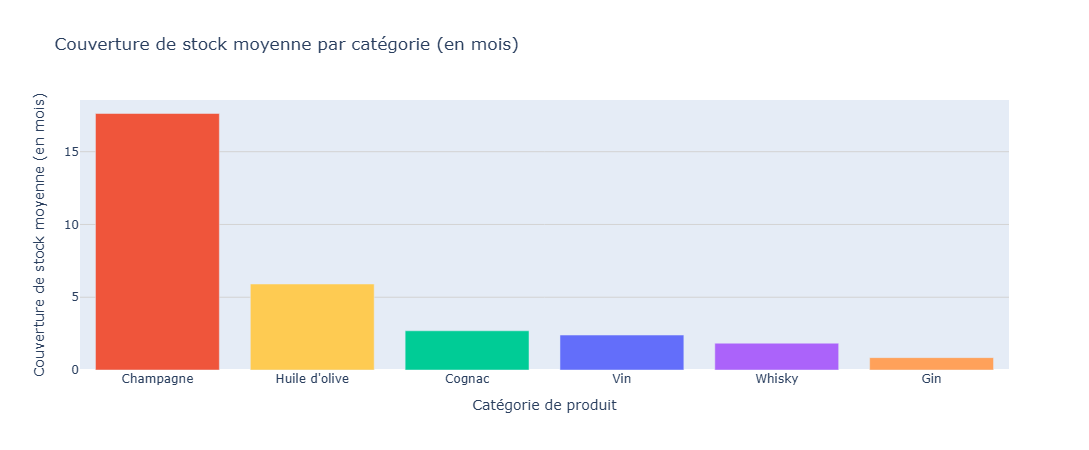

In [100]:
#Calculer la couverture de stock moyenne par catégorie
couverture_stock_moyenne_par_cat = (
    df_final.groupby('product_type')['mois_stock']
    .mean()
    .sort_values(ascending=False)
    .reset_index(name='mois_stock_moyenne')
)

#Visualiser la couverture de stock moyenne par catégorie
fig = px.bar(
    couverture_stock_moyenne_par_cat,
    x='product_type',
    y='mois_stock_moyenne',
    color='product_type',
    color_discrete_map=couleurs_categories,
    title="Couverture de stock moyenne par catégorie (en mois)",
    labels={
        'product_type': 'Catégorie de produit',
        'mois_stock_moyenne': 'Couverture de stock moyenne (en mois)'
    }
)

fig.update_layout(
    width=800,
    height=450,
    showlegend=False,
    xaxis_type='category',
    yaxis=dict(showgrid=True, gridcolor='lightgray')
)

fig.show()

In [101]:
#Lister les articles sans couverture calculable par catégorie
nan_mois_stock_categorie = (
    df_final.groupby('product_type')['mois_stock']
    .agg(
        nb_articles='size',
        nb_nan=lambda x: x.isna().sum()
    )
    .reset_index()
)

nan_mois_stock_categorie['proportion_nan_%'] = (
    nan_mois_stock_categorie['nb_nan']
    / nan_mois_stock_categorie['nb_articles'] * 100
)

display(nan_mois_stock_categorie)

,product_type,nb_articles,nb_nan,proportion_nan_%
0,Champagne,28,2,7.14
1,Cognac,8,1,12.50
2,Gin,2,0,0.00
3,Huile d'olive,3,0,0.00
4,Vin,658,21,3.19
5,Whisky,14,1,7.14


### Valorisation de stock

In [102]:
#Calculer la valorisation du stock par article
df_final['valorisation_stock'] = (
    df_final['purchase_price'] * df_final['stock_quantity'].clip(lower=0)
)

print(
    "La valorisation totale des stocks est de {:.2f} €."
    .format(df_final['valorisation_stock'].sum())
)

La valorisation totale des stocks est de 277022.17 €.


In [103]:
#Calculer la valorisation totale des stocks par catégorie
valorisation_euro_par_categorie = (
    df_final.groupby('product_type')['valorisation_stock']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

#Visualiser la répartition de la valorisation des stocks par catégorie
fig = px.pie(
    valorisation_euro_par_categorie,
    names='product_type',
    values='valorisation_stock',
    color='product_type',
    color_discrete_map=couleurs_categories,
    title="Répartition de la valorisation des stocks par catégorie"
)

fig.update_traces(
    textinfo='percent',
    textposition='inside',
    insidetextorientation='horizontal',
    hovertemplate='%{label}<br>Valorisation : %{value:,.2f} €<br>Part : %{percent}<extra></extra>'
)

fig.update_layout(
    width=850,
    height=450,
    showlegend=True,
    legend=dict(
        title='Catégorie de produit',
        x=1,
        y=0.5,
        xanchor='left',
        yanchor='middle'
    ),
    margin=dict(t=80, b=30, l=30, r=150)
)

fig.show()

In [104]:
#Ajouter la colonne « valorisation_stock » au tableau des articles sans couverture calculable
nan_mois_stock_categorie['valorisation_stock'] = (
    df_final[df_final['mois_stock'].isna()]
    .groupby('product_type')['valorisation_stock']
    .sum()
    .reindex(nan_mois_stock_categorie['product_type'], fill_value=0)
    .to_numpy()
)

display(nan_mois_stock_categorie)

,product_type,nb_articles,nb_nan,proportion_nan_%,valorisation_stock
0,Champagne,28,2,7.14,"14,606.06"
1,Cognac,8,1,12.50,353.34
2,Gin,2,0,0.00,0.00
3,Huile d'olive,3,0,0.00,0.00
4,Vin,658,21,3.19,0.00
5,Whisky,14,1,7.14,0.00


### Quantité en stock

In [105]:
#Calculer la quantité totale en stock
print(
    "La quantité totale en stock est de {:.0f} unités."
    .format(df_final['stock_quantity'].clip(lower=0).sum())
)

La quantité totale en stock est de 16717 unités.


In [106]:
#Calculer la quantité totale en stock par catégorie
quantite_stock_par_categorie = (
    df_final.assign(
        stock_disponible=df_final['stock_quantity'].clip(lower=0)
    )
    .groupby('product_type')['stock_disponible']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

#Visualiser la répartition des quantités en stock par catégorie
fig = px.pie(
    quantite_stock_par_categorie,
    names='product_type',
    values='stock_disponible',
    color='product_type',
    color_discrete_map=couleurs_categories,
    title="Répartition des quantités en stock par catégorie"
)

fig.update_traces(
    textinfo='percent',
    textposition='inside',
    insidetextorientation='horizontal',
    hovertemplate='%{label}<br>Quantité : %{value:,.0f} unités<br>Part : %{percent}<extra></extra>'
)

fig.update_layout(
    width=850,
    height=450,
    showlegend=True,
    legend=dict(
        title='Catégorie de produit',
        x=1,
        y=0.5,
        xanchor='left',
        yanchor='middle'
    ),
    margin=dict(t=80, b=30, l=30, r=150)
)

fig.show()

In [107]:
#Ajouter la colonne « stock_quantity » au tableau des articles sans couverture calculable
nan_mois_stock_categorie['stock_quantity'] = (
    df_final[df_final['mois_stock'].isna()]
    .groupby('product_type')['stock_quantity']
    .sum()
    .reindex(nan_mois_stock_categorie['product_type'], fill_value=0)
    .to_numpy()
)

display(nan_mois_stock_categorie)

,product_type,nb_articles,nb_nan,proportion_nan_%,valorisation_stock,stock_quantity
0,Champagne,28,2,7.14,"14,606.06",242
1,Cognac,8,1,12.50,353.34,13
2,Gin,2,0,0.00,0.00,0
3,Huile d'olive,3,0,0.00,0.00,0
4,Vin,658,21,3.19,0.00,0
5,Whisky,14,1,7.14,0.00,0


**Impact des articles sans couverture calculable**  
La proportion de références exclues du calcul de couverture reste relativement faible.  
Toutefois, les catégories Champagne et Cognac présentent des stocks non négligeables :  
- **Champagne :** 2 références (7,14 %), représentant 242 bouteilles et 14 606,06 € de stock.
- **Cognac :** 1 référence (12,50 %), représentant 13 unités et 353,34 € de stock.  
Cette exclusion limite la représentativité de l'indicateur et peut masquer certaines situations de stockage.

## 5.4 Analyse du taux de marge

**Hypothèse et limites du calcul du taux de marge**  
Les données sources ne précisent pas si les prix de vente et les prix d'achat sont exprimés HT ou TTC. Contrairement au projet initial, aucune conversion de TVA n'est donc appliquée afin d'éviter toute hypothèse non vérifiée.  
Le taux de marge calculé à partir des prix disponibles est utilisé à titre exploratoire. Son interprétation nécessite une confirmation préalable de la comparabilité des bases de prix auprès des responsables métier.  

In [108]:
#Calculer le taux de marge par article
df_final['taux_marge'] = (
    (df_final['price'] - df_final['purchase_price']) /
    df_final['purchase_price'].where(df_final['purchase_price'] > 0)
) *100

In [109]:
#Analyser les statistiques descriptives de la colonne « taux_marge »
df_final['taux_marge'].describe()

count   713.00
mean     93.23
std      11.56
min     -83.67
25%      87.89
50%      93.53
75%      99.55
max     129.69
Name: taux_marge, dtype: float64

In [110]:
#Identifier les articles présentant un taux de marge nul ou négatif
df_final[df_final['taux_marge'] <= 0]

,product_id,sku,post_title,product_type,purchase_price,price,total_sales,stock_status,stock_quantity,z_score,outliers_iqr,outliers_iqr_categorie,ca_par_article,mois_stock,valorisation_stock,taux_marge
38,4355,12589,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,Champagne,77.48,12.65,0.00,instock,97,-0.71,False,False,0.00,NaN,"7,515.56",-83.67


Les prix de vente et les prix d'achat des articles présentant un taux de marge nul ou négatif nécessitent une vérification complémentaire afin de déterminer les éventuelles actions à entreprendre.

In [111]:
#Sélectionner les articles présentant un taux de marge positif
df_marge_positive = df_final[df_final['taux_marge'] > 0]
#Analyser les statistiques descriptives de la colonne « taux_marge »
df_marge_positive['taux_marge'].describe()

count   712.00
mean     93.48
std       9.47
min      55.40
25%      87.89
50%      93.53
75%      99.55
max     129.69
Name: taux_marge, dtype: float64

In [112]:
#Calculer le taux de marge moyen par catégorie
df_taux_marge_type_produit = (
    df_final.groupby('product_type')['taux_marge']
    .mean()
    .round(2)
    .sort_values(ascending=False)
    .reset_index()
)

#Visualiser le taux de marge moyen par catégorie
fig = px.scatter(
    df_taux_marge_type_produit,
    x='product_type',
    y='taux_marge',
    color='product_type',
    color_discrete_map=couleurs_categories,
    title="Taux de marge moyen par catégorie",
    labels={
        'product_type': 'Catégorie de produit',
        'taux_marge': 'Taux de marge moyen (%)'
    }
)

fig.update_traces(marker=dict(size=12))

fig.update_layout(
    width=800,
    height=400,
    showlegend=False,
    xaxis_type='category',
    yaxis=dict(showgrid=True, gridcolor='lightgray')
)

fig.show()

# 6. Analyse multivariée

## 6.1 Analyse des corrélations entre les variables stock, sales et price

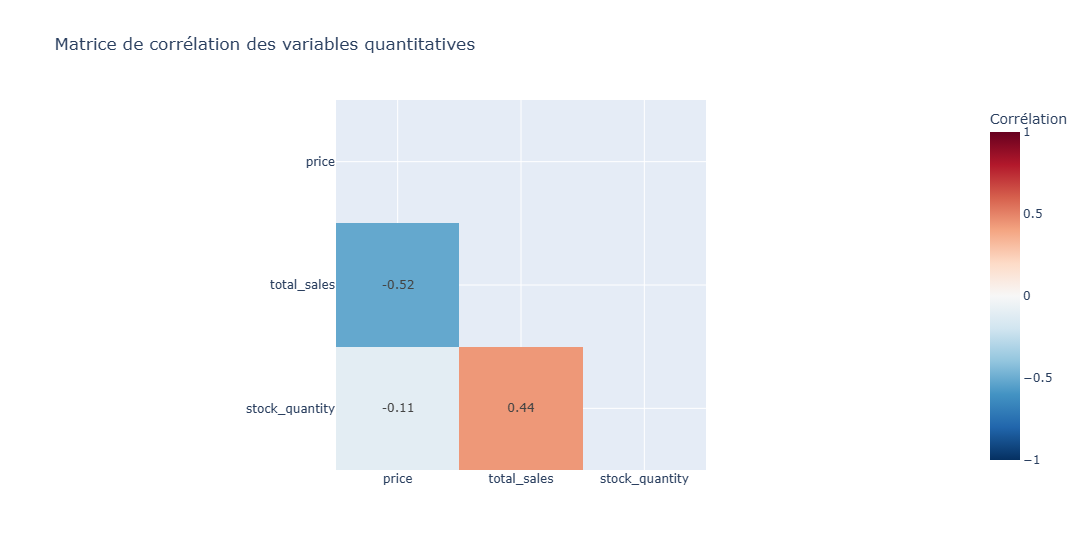

In [113]:
#Calculer la matrice de corrélation
corr_matrix = df_final[
    ['price', 'total_sales', 'stock_quantity']
].corr()

#Créer un masque pour afficher uniquement la moitié inférieure
corr_matrix_masked = corr_matrix.mask(
    np.triu(np.ones(corr_matrix.shape, dtype=bool))
)

#Générer la heatmap interactive
fig = px.imshow(
    corr_matrix_masked,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    zmin=-1,
    zmax=1,
    aspect='equal',
    title="Matrice de corrélation des variables quantitatives"
)

fig.update_layout(
    width=800,
    height=550,
    coloraxis_colorbar_title="Corrélation"
)

fig.show()

**Analyse des corrélations**  
L'analyse se concentre sur trois variables quantitatives principales : le prix de vente, les quantités vendues et les quantités en stock.  
Les indicateurs dérivés sont exclus afin de limiter les redondances et de faciliter l'interprétation des relations observées.  

**Interprétation des résultats**
- **Stock vs. Ventes en qté : 0,44**  
Corrélation positive modérée : les articles présentant des quantités en stock plus élevées tendent également à enregistrer des volumes de ventes plus importants.  
Toutefois, cette relation reste modérée, ce qui soulève une question sur l'adéquation entre les niveaux de stock et les volumes de ventes. Une analyse complémentaire permettrait d'identifier les articles présentant des stocks élevés malgré de faibles ventes, ou inversement.
- **Ventes en qté vs. Prix : -0,52**  
Corrélation négative modérée : les articles présentant des prix plus élevés tendent à enregistrer des volumes de ventes plus faibles.  

## 6.2 KPI 1 : Couverture de stock

In [114]:
#Afficher les statistiques descriptives de la couverture de stock par catégorie
df_final.groupby('product_type')['mois_stock'].describe()

,count,mean,std,min,25%,50%,75%,max
product_type,,,,,,,,
Champagne,26.00,17.63,6.99,0.00,12.67,16.92,22.73,31.25
Cognac,7.00,2.69,1.06,1.33,1.90,2.80,3.33,4.25
Gin,2.00,0.85,0.21,0.70,0.77,0.85,0.93,1.00
Huile d'olive,3.00,5.91,5.77,1.80,2.61,3.43,7.96,12.50
Vin,637.00,2.40,1.33,0.00,1.80,2.38,3.00,19.00
Whisky,13.00,1.84,1.00,1.00,1.33,1.50,1.67,4.00


**Impact des exclusions sur la distribution de la couverture de stock**  
Pour le Champagne et le Cognac, les couvertures médianes de 16,92 et 2,80 mois sont calculées respectivement sur 26 et 7 références ayant enregistré des ventes en octobre. Les références sans ventes sont exclues du calcul.  
L'intégration de nouvelles données de ventes pourrait permettre de calculer la couverture des références actuellement exclues et d'affiner l'analyse de la distribution. L'ampleur et le sens de cet effet restent toutefois indéterminés à ce stade.

### « total_sales » > 0

In [115]:
#Classer les articles par valorisation du stock décroissante
#afin d'examiner les couvertures de stock les plus élevées parmi les articles à forte valorisation et d'évaluer leur immobilisation financière
articles_verif_surstock = (
    df_final.loc[
        df_final['total_sales'] > 0,
        ['sku', 'product_type', 'stock_quantity', 'ca_par_article',
         'total_sales', 'mois_stock', 'valorisation_stock']
    ]
    .sort_values('valorisation_stock', ascending=False)
    .reset_index(drop=True)
)

#Afficher les 10 premiers articles pour identifier les risques de surstockage
articles_verif_surstock.head(10)

,sku,product_type,stock_quantity,ca_par_article,total_sales,mois_stock,valorisation_stock
0,14983,Champagne,98,"1,147.80",6.00,16.33,"11,373.88"
1,14923,Champagne,138,675.00,5.00,27.60,"11,085.54"
2,13914,Champagne,136,672.00,6.00,22.67,"9,329.60"
3,12588,Champagne,145,556.50,7.00,20.71,"6,858.50"
4,12587,Champagne,127,"1,113.00",14.00,9.07,"5,830.57"
5,13853,Champagne,112,599.20,7.00,16.00,"5,816.16"
6,13913,Champagne,101,781.20,9.00,11.22,"5,063.13"
7,1366,Champagne,123,354.00,6.00,20.50,"4,360.35"
8,12586,Champagne,125,295.00,5.00,25.00,"4,345.00"
9,7818,Champagne,142,343.00,7.00,20.29,"4,261.42"


**Surstock :**  
Les données disponibles, limitées au mois d'octobre, ne permettent pas de confirmer une situation de surstock. Une couverture élevée indique seulement un niveau de stock important par rapport aux ventes observées.  
La saisonnalité, notamment pour le Champagne à l'approche des fêtes de fin d'année, ainsi que les stratégies d'approvisionnement peuvent également expliquer ce niveau de stock. L'analyse vise donc à identifier les situations nécessitant une attention particulière, sans conclure à un surstock avéré.  

**Constats :**  
- **Champagne :** Les dix références présentant les valorisations de stock les plus élevées appartiennent à cette catégorie. Leurs couvertures de stock, comprises entre 9,07 et 27,60 mois, suggèrent un niveau de stock important au regard des ventes d'octobre.

**Perspective d'amélioration :**  
Une analyse métier complémentaire, appuyée sur un suivi régulier des ventes et des niveaux de stock, permettrait de **définir des seuils d'alerte pertinents pour la couverture de stock**, afin d'identifier les risques de surstockage et de faciliter la priorisation des actions de gestion des stocks.

In [116]:
#Filtrer les articles dont la quantité en stock est nulle
articles_verif_rupture = (
    df_final.loc[
        df_final['stock_quantity'] == 0,
        ['sku', 'product_type', 'stock_quantity', 'total_sales', 'ca_par_article']
    ]
    .sort_values('ca_par_article', ascending=False)
    .reset_index(drop=True)
)

#Compter le nombre d'articles par catégorie présentant un risque de rupture de stock
categories_verif_rupture = (
    articles_verif_rupture
    .groupby('product_type')
    .size()
)
display(categories_verif_rupture)

#Afficher les articles présentant un risque de rupture de stock
display(articles_verif_rupture)

product_type
Champagne     1
Vin          42
Whisky        1
dtype: int64

,sku,product_type,stock_quantity,total_sales,ca_par_article
0,15940,Champagne,0,11.00,"2,475.00"
1,16129,Vin,0,9.00,391.50
2,15710,Vin,0,4.00,312.00
3,14950,Vin,0,22.00,279.40
4,14844,Vin,0,9.00,250.20
5,15134,Vin,0,6.00,231.00
6,14253,Vin,0,9.00,219.60
7,16154,Vin,0,8.00,216.00
8,2361,Vin,0,4.00,200.00
9,16323,Vin,0,14.00,197.40


In [117]:
#Identifier les articles de la catégorie Vin avec un stock nul et appartenant aux 20 % des articles générant le moins de CA
articles_rupture_vin = produits_bottom20_ca_vin.merge(
    articles_verif_rupture[['sku']],
    on='sku',
    how='inner'
)

#Afficher le nombre d'articles concernés
print("Nombre d'articles communs :", len(articles_rupture_vin))
#Afficher les articles concernés 
display(articles_rupture_vin[
    ['sku', 'post_title', 'stock_quantity',
     'total_sales', 'ca_par_article']
])

Nombre d'articles communs : 26


,sku,post_title,stock_quantity,total_sales,ca_par_article
0,16030,Clos du Mont-Olivet Châteauneuf-du-Pape Blanc ...,0,0.00,0.00
1,13032,Château de La Liquière Faugères Tucade 2015,0,0.00,0.00
2,13078,Le Vieux Donjon Châteauneuf-du-Pape 2013,0,0.00,0.00
3,15745,Borie La Vitarèle Saint-Chinian Midi Rouge 2015,0,0.00,0.00
4,15318,I Fabbri Chianti Classico Gran Selezione 2015,0,0.00,0.00
5,13416,Emile Boeckel Gewurztraminer Grand Cru Zotzenb...,0,0.00,0.00
6,15149,Catherine et Claude Maréchal Volnay 2017,0,0.00,0.00
7,14977,Pierre Gaillard Côtes-du-Rhône Blanc Les Gendr...,0,0.00,0.00
8,16045,Jeanne Gaillard IGP Collines Rhodaniennes Syra...,0,0.00,0.00
9,16289,Tempier Bandol Rosé 2019,0,0.00,0.00


**Rupture de stock :**  
Les données disponibles ne permettent pas d'établir de lien de causalité entre les ventes et les stocks.  
Toutefois, une rupture de stock peut empêcher des ventes supplémentaires jusqu'au réapprovisionnement. L'analyse suivante repose sur cette logique opérationnelle.

**Constats et hypothèses :**  
- **Champagne :** une référence à stock nul a enregistré 11 unités vendues en octobre. La rupture pourrait avoir limité les ventes supplémentaires.
- **Whisky :** une référence à stock nul n'a enregistré aucune vente. L'absence de stock pourrait expliquer cette situation, sans exclure une absence de demande.
- **Vin :** parmi les 42 références à stock nul, 26 figurent parmi les 136 références générant le moins de CA (bottom 20 %). Ce constat invite à nuancer l'interprétation des faibles CA : ils pourraient être liés à une disponibilité limitée des produits plutôt qu'à une demande insuffisante.

**Perspectives d'amélioration :**  
- **Réapprovisionnement :** examiner en priorité les références à stock nul, notamment celles dont les ventes pourraient être limitées par une rupture.
- **Suivi des stocks :** un suivi régulier des ventes et des stocks permettrait de définir un stock cible adapté à chaque référence, afin d'anticiper les ruptures et d'orienter les décisions de réapprovisionnement.

### « total_sales » = 0

In [118]:
#Identifier les articles sans ventes présentant les valeurs de stock les plus élevées
articles_sans_ventes = df_final.loc[
    (df_final['total_sales'] == 0) &
    (df_final['stock_quantity'] > 0),
    ['sku', 'product_type', 'stock_quantity',
     'total_sales', 'valorisation_stock']
].sort_values('valorisation_stock', ascending=False).reset_index(drop=True)

articles_sans_ventes.head()

,sku,product_type,stock_quantity,total_sales,valorisation_stock
0,12589,Champagne,97,0.00,"7,515.56"
1,4679,Champagne,145,0.00,"7,090.50"
2,523,Cognac,13,0.00,353.34


**Constats et perspectives :**  
- Trois références présentent un stock positif sans ventes enregistrées en octobre, dont deux références de Champagne affichant chacune une valorisation de stock supérieure à 7 000 €.
- Cette situation ne permet pas de conclure à un surstockage, notamment en raison de la période d'observation limitée et de la saisonnalité potentielle des ventes, particulièrement pour le Champagne.
- Un suivi des ventes et des niveaux de stock sur plusieurs mois permettrait de mieux évaluer leur situation et de déterminer si des ajustements de stock sont nécessaires.

## 6.3 KPI 2 : GMROI

**GMROI – Analyse exploratoire**  
Le GMROI permet d'évaluer la rentabilité des investissements en stocks en rapportant la marge brute à la valeur moyenne du stock au coût d'achat.

Étant donné que les données de ventes couvrent uniquement le mois d'octobre :
- Le GMROI estimé est calculé en rapportant la marge brute générée sur cette période à la valorisation du stock disponible au 31 octobre, date d'extraction des données. En l'absence de données sur le stock moyen, cette valorisation est utilisée comme approximation. Cette méthode peut entraîner une surestimation ou une sous-estimation du GMROI selon l'évolution des stocks. Le résultat constitue donc une estimation indicative, à interpréter avec prudence, et ne peut pas être assimilé au GMROI standard.
- Pour les références sans ventes en octobre, le GMROI estimé est nul lorsque la valorisation du stock est positive, sans pour autant conclure à une absence de rentabilité.
- Pour les références sans stock au 31 octobre, le GMROI estimé ne peut pas être calculé et est donc défini comme NaN.  

Compte tenu de ces limites, cet indicateur est conservé à titre exploratoire. Une exploitation plus fiable nécessiterait des données historiques permettant de calculer la valeur moyenne du stock sur la période étudiée.

### Étape 1 – Calculer la marge totale par article

In [119]:
#Calculer la contribution à la marge brute par article
df_final['marge_totale'] = (
    (df_final['price'] - df_final['purchase_price'])
    * df_final['total_sales']
)

### Étape 2 – Analyser la contribution à la marge, les ventes et les stocks par catégorie

In [120]:
#Analyser la contribution à la marge, les ventes et les stocks par catégorie
categories_marge = (
    df_final.groupby('product_type')
    .agg(
        nb_articles=('sku', 'count'),
        marge_totale=('marge_totale', 'sum'),
        ventes_totales=('total_sales', 'sum'),
        stock_total=('stock_quantity', 'sum')
    )
    .sort_values('marge_totale', ascending=False)
    .reset_index()
)

#Calculer la part de chaque catégorie dans la marge totale
categories_marge.insert(
    3,
    'part_marge_pct',
    categories_marge['marge_totale'] / categories_marge['marge_totale'].sum() * 100
)

display(categories_marge)

,product_type,nb_articles,marge_totale,part_marge_pct,ventes_totales,stock_total
0,Vin,658,"59,622.76",87.01,"5,456.00",13469
1,Champagne,28,"5,178.80",7.56,169.00,2894
2,Cognac,8,"1,717.23",2.51,35.00,99
3,Whisky,14,"1,554.14",2.27,48.00,85
4,Gin,2,263.76,0.38,14.00,11
5,Huile d'olive,3,188.74,0.28,22.00,158


### Étape 3 – Évaluer la productivité du stock par catégorie

In [121]:
#Ajouter la valorisation du stock par catégorie
categories_marge['valorisation_stock'] = (
    df_final.groupby('product_type')['valorisation_stock'].sum()
    .reindex(categories_marge['product_type']).to_numpy()
)

#Calculer la marge générée par euro de stock immobilisé
categories_marge['gmroi'] = (
    categories_marge['marge_totale'] /
    categories_marge['valorisation_stock'].replace(0, np.nan)
)

display(categories_marge)

,product_type,nb_articles,marge_totale,part_marge_pct,ventes_totales,stock_total,valorisation_stock,gmroi
0,Vin,658,"59,622.76",87.01,"5,456.00",13469,"146,020.51",0.41
1,Champagne,28,"5,178.80",7.56,169.00,2894,"121,639.98",0.04
2,Cognac,8,"1,717.23",2.51,35.00,99,"4,461.84",0.38
3,Whisky,14,"1,554.14",2.27,48.00,85,"2,767.36",0.56
4,Gin,2,263.76,0.38,14.00,11,188.76,1.40
5,Huile d'olive,3,188.74,0.28,22.00,158,"1,943.72",0.10


**Constats et perspectives :**  
- **Vin :** Principal contributeur à la marge totale (87,01 %) et catégorie présentant la valorisation de stock la plus élevée (146 020,51 €), avec un GMROI estimé de 0,41, se classant au troisième rang parmi les six catégories.
- **Champagne :** Présente la deuxième valorisation de stock la plus élevée (121 639,98 €), avec un GMROI estimé de 0,04, le plus faible parmi les six catégories.
- **Perspective :** Un suivi des ventes et des stocks sur plusieurs mois, tenant notamment compte de la saisonnalité du Champagne, permettrait de mieux évaluer sa situation et d'orienter d'éventuelles décisions d'ajustement des stocks.

### Étape 4 – Identifier les articles prioritaires pour l'optimisation des stocks de Champagne

In [122]:
#Analyser la marge, les ventes et les stocks des articles de Champagne
articles_champagne = df_final.loc[
    df_final['product_type'] == 'Champagne',
    ['sku', 'marge_totale', 'total_sales', 'stock_quantity',
     'mois_stock', 'valorisation_stock']
].copy()

#Calculer la productivité du stock par article
articles_champagne['gmroi'] = (
    articles_champagne['marge_totale'] /
    articles_champagne['valorisation_stock'].replace(0, np.nan)
)

#Classer les articles par valorisation du stock décroissante
articles_champagne = articles_champagne.sort_values(
    'valorisation_stock', ascending=False
).reset_index(drop=True)

articles_champagne.head(10)

,sku,marge_totale,total_sales,stock_quantity,mois_stock,valorisation_stock,gmroi
0,14983,451.44,6.00,98,16.33,"11,373.88",0.04
1,14923,273.35,5.00,138,27.60,"11,085.54",0.02
2,13914,260.40,6.00,136,22.67,"9,329.60",0.03
3,12589,-0.00,0.00,97,NaN,"7,515.56",-0.00
4,4679,0.00,0.00,145,NaN,"7,090.50",0.00
5,12588,225.40,7.00,145,20.71,"6,858.50",0.03
6,12587,470.26,14.00,127,9.07,"5,830.57",0.08
7,13853,235.69,7.00,112,16.00,"5,816.16",0.04
8,13913,330.03,9.00,101,11.22,"5,063.13",0.07
9,1366,141.30,6.00,123,20.50,"4,360.35",0.03


**Constats et perspectives :**  
- **SKU 14983, 14923 et 13914 :** Présentent les valorisations de stock les plus élevées, associées à des couvertures importantes et à des GMROI estimés relativement faibles. Leur situation doit être évaluée en tenant compte de la saisonnalité du Champagne avant toute décision opérationnelle.
- **SKU 4679 :** Aucune vente enregistrée en octobre, malgré une valorisation de stock de 7 090,50 €. Un suivi des ventes sur plusieurs mois, tenant compte de la saisonnalité, permettrait de mieux évaluer sa situation.
- **SKU 12589 :** Aucune vente enregistrée en octobre, avec une valorisation de stock de 7 515,56 € et un taux de marge négatif. Une vérification de ce taux est nécessaire avant toute interprétation ou décision opérationnelle.

# 7. Mise à disposition de la nouvelle table sur un fichier Excel

In [123]:
#Mettre le jeu de données df_final sur un fichier Excel
df_final.to_excel('df_merge_bottleneck.xlsx', index=False)